# Figure 1 & 2 kernels

(Fig 1A) the four decoded example posteriors on one color scale, (Fig 2A) the ten transition
kernels as PMFs, and (Fig 1B) the SR -> M^T M (omega, gamma) extremes. The cells above the plots only define helpers and compute what the plots draw.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Lab shared style (color cycle + despined axes).
from replay_hmm.plots.style import apply_analysis_plot_style
apply_analysis_plot_style()

In [2]:
# --- Position axis ---------------------------------------------------------
HALF_WIDTH = 15                       # bins on each side of the previous position
positions = np.arange(-HALF_WIDTH, HALF_WIDTH + 1)   # -15 ... 15  -> 31 bins

# --- Heuristic kernels -----------------------------------------------------
def stationary_kernel(pos):
    k = np.zeros_like(pos, dtype=float)
    k[pos == 0] = 1.0                 # all mass at the previous position
    return k

def continuous_kernel(pos, sigma=2.0):
    k = np.exp(-0.5 * (pos / sigma) ** 2)   # Gaussian random walk
    return k / k.sum()

def fragmented_kernel(pos):
    k = np.ones_like(pos, dtype=float)      # uniform over all bins
    return k / k.sum()

# --- Movement / SR / TCM-SR kernels on the same position grid --------------
# Row-stochastic construction:
#   Movement  T   one-step transition (forward-biased random walk)
#   SR        M   = T (I - gamma T)^{-1}
#   TCM-SR    P   = M_SC @ M_CS, M_SC = (1-alpha) M.T + alpha I, M_CS = M
def sr_family_kernels(pos, gamma=0.8, alpha=0.5,
                      p_back=0.20, p_stay=0.25, p_fwd=0.55, pad=20):
    """Return (movement, SR, TCM-SR) PMFs sampled on the ``pos`` grid.

    Built on a padded ring so the window is free of boundary effects, then the
    current-position row is sliced onto ``pos`` (relative position).
    """
    n = len(pos)
    N = n + 2 * pad
    c = N // 2
    T = np.zeros((N, N))
    for i in range(N):
        T[i, (i - 1) % N] += p_back
        T[i, i] += p_stay
        T[i, (i + 1) % N] += p_fwd
    I_N = np.eye(N)
    M = T @ np.linalg.inv(I_N - gamma * T)

    def rownorm(A, eps=1e-12):
        s = A.sum(axis=1, keepdims=True); s[s < eps] = 1.0
        return A / s

    P = rownorm(((1 - alpha) * M.T + alpha * I_N) @ M)   # TCM-SR retrieval

    cols = c + pos                       # pos is symmetric about 0
    move = T[c][cols];      move /= move.sum()
    sr = M[c][cols];        sr /= sr.sum()
    tcmsr = P[c][cols];     tcmsr /= tcmsr.sum()
    return move, sr, tcmsr

kernels = {
    "Stationary":  stationary_kernel(positions),
    "Continuous":  continuous_kernel(positions, sigma=2.0),
    "Fragmented":  fragmented_kernel(positions),
}

In [3]:
# ---------------------------------------------------------------------------
# Shared decoding and plotting helpers for the posterior grid.
# ---------------------------------------------------------------------------
seq_duration = 0.6
VMAX = 0.20
LABEL_FS, TICK_FS = 8, 7   # axis/colorbar labels; tick labels and r annotation

# Colormap: light teal-gray (low prob) -> dark indigo (high prob).
cell_cmap = LinearSegmentedColormap.from_list(
    "kernel", ['#f7fcfd','#e0ecf4','#bfd3e6','#9ebcda','#8c96c6','#8c6bb1','#88419d','#6e016b']
)


def weighted_corr(post, t, x):
    """Posterior-weighted correlation between time and decoded position.

    Each (time, position) cell is weighted by its posterior mass post[t, x];
    this is the standard replay sequence score (e.g. Silva et al. 2015).
    """
    w = post
    T = t[:, None] * np.ones_like(post)
    X = np.ones_like(post) * x[None, :]
    sw = w.sum()
    mt = (w * T).sum() / sw
    mx = (w * X).sum() / sw
    cov = (w * (T - mt) * (X - mx)).sum() / sw
    vt = (w * (T - mt) ** 2).sum() / sw
    vx = (w * (X - mx) ** 2).sum() / sw
    return cov / np.sqrt(vt * vx)


def decode_posterior(spike_times, duration, n_pos=60, place_sigma=0.06,
                     peak_rate=30.0, baseline=0.5, dt=0.02):
    """One-step Bayesian decoder (Zhang et al. 1998) over evenly spaced place fields.

    log P(x | n_t) = sum_i n_it log f_i(x) - dt sum_i f_i(x)   (up to a constant)
    Neuron i's field is centered at position i / (n_cells - 1).
    Returns (posterior (n_time, n_pos), time_centers, pos_grid, r).
    """
    centers = np.linspace(0, 1, len(spike_times))
    pos = np.linspace(0, 1, n_pos)
    F = baseline + peak_rate * np.exp(-0.5 * ((pos[None, :] - centers[:, None]) / place_sigma) ** 2)
    edges = np.arange(0, duration + dt, dt)
    tc = 0.5 * (edges[:-1] + edges[1:])
    cnt = np.stack([np.histogram(s, bins=edges)[0] for s in spike_times])
    lp = cnt.T @ np.log(F) - dt * F.sum(0)[None, :]
    lp -= lp.max(1, keepdims=True)
    P = np.exp(lp); P /= P.sum(1, keepdims=True)
    return P, tc, pos, weighted_corr(P, tc, pos)


def simulate_and_decode(traj_x, duration=seq_duration, n_cells=30, place_sigma=0.06,
                        peak_rate=30.0, baseline=0.5, dt=0.02, seed=1):
    """Place-cell spikes driven by a target position trajectory, then decoded.

    traj_x : target position in [0, 1] on a fine time grid over [0, duration].
    Returns (spike_times, posterior (n_time, n_pos), time_centers, pos_grid, r).
    """
    rng = np.random.default_rng(seed)
    centers = np.linspace(0, 1, n_cells)
    tt = np.linspace(0, duration, len(traj_x))
    dt_fine = tt[1] - tt[0]

    spikes = []
    for pk in centers:
        rate = baseline + peak_rate * np.exp(-0.5 * ((traj_x - pk) / place_sigma) ** 2)
        cnt_fine = rng.poisson(rate * dt_fine)
        st = np.repeat(tt, cnt_fine) + rng.uniform(0, dt_fine, cnt_fine.sum())
        spikes.append(np.sort(np.clip(st, 0, duration)))

    return (spikes, *decode_posterior(spikes, duration, place_sigma=place_sigma,
                                      peak_rate=peak_rate, baseline=baseline, dt=dt))


def draw_posterior(ax, post, duration, wc):
    """Posterior heatmap with the shared ticks, color scale and r annotation; returns the image."""
    im = ax.imshow(post.T, origin="lower", aspect="auto", cmap=cell_cmap,
                   extent=[0, duration, 0, 1], vmax=VMAX)
    ax.set_yticks(np.linspace(0, 1, 4))
    ax.set_yticklabels([0, 40, 80, 120])
    ax.set_xticks(np.linspace(0,1,4) * duration)
    ax.set_xticklabels([0,50,100,150])
    ax.tick_params(labelsize=TICK_FS)
    ax.text(0.05, 0.93, f"r = {wc:.2f}", transform=ax.transAxes,
            fontsize=TICK_FS, va="top", ha="left", color="k",)
    return im


def add_posterior_colorbar(fig, im, ax):
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Posterior", fontsize=LABEL_FS)
    cbar.ax.tick_params(labelsize=TICK_FS)
    cbar.set_ticks([0.0, VMAX / 2, VMAX])
    return cbar

In [4]:
# ---------------------------------------------------------------------------
# The four decoded posteriors for the grid, PANELS[name] = (posterior, r).
# ---------------------------------------------------------------------------
PANELS = {}

# --- Linear: a (relatively) sequential spike train across sorted neurons ---
rng = np.random.default_rng(3)
lam = 3                                # avg spikes per neuron
n_neurons = 30
field_centers = np.linspace(0.08, 0.92, n_neurons) * seq_duration  # ordered firing
jitter = 0.05                          # s, spread of each neuron's burst
p_background = 0.2                     # chance of an extra out-of-sequence spike

spike_times = []
for c in field_centers:
    spikes = rng.normal(c, jitter, size=rng.poisson(lam))
    if rng.random() < p_background:                # occasional off-sequence spike
        spikes = np.append(spikes, rng.uniform(0, seq_duration))
    spike_times.append(np.clip(spikes, 0, seq_duration))

post, _, _, wc = decode_posterior(spike_times, seq_duration)
PANELS["linear"] = post, wc

# Reversal and jumps: specify the decoded trajectory x(t) (position vs. normalized time
# in [0, 1]); the posterior follows it because decoded position = field center of the
# firing cells.
tg = np.linspace(0, 1, 240)

# --- Reversal (out-and-back) ---
x_reversal = np.where(tg < 0.5,
                  0.3 + 0.3 * (1 - np.abs(2 * tg - 1)),                 # high block, slight rise
                  0.8 - 0.2 * (1 + (2 * tg - 1)))         # jump down, then rise
_, post, _, _, wc = simulate_and_decode(x_reversal)
PANELS["reversal"] = post, wc

# --- Jumps (teleports) between three hover locations ---
# Low block, a discontinuity forward to an intermediate block, then a second jump forward
# to a high block, so the skippy replay progresses with positive correlation.
x_jump = np.select([tg < 1 / 4, tg < 2 / 3],
                   [0.2 + 0.06 * tg,                   # low block, slight drift
                    0.55 + 0.03 * tg],                  # intermediate block
                   0.82 + 0.06 * tg)                    # high block
_, post, _, _, wc = simulate_and_decode(x_jump)
PANELS["jumps"] = post, wc

# --- TCM-SR rollout ---
# Hidden-state sequence sampled from the TCM-SR retrieval kernel, then decoded with the
# same simulate_and_decode() call. With alpha < 1, P mixes the forward SR with its
# transpose, so the sequence skips ahead and can then turn back and skip home -- a jumpy
# reversal, i.e. a generalized rollout.
def build_tcmsr_P(n_states, gamma=0.8, alpha=0.8, p_back=0.0, p_stay=0.1, p_fwd=0.9):
    """Row-stochastic TCM-SR retrieval kernel P on a line of states.

    Same construction as sr_family_kernels, returned as the full transition
    matrix so we can sample a Markov chain of hidden states from it.
    """
    T = np.zeros((n_states, n_states))
    for i in range(n_states):
        if i > 0:
            T[i, i - 1] += p_back
        if i < n_states - 1:
            T[i, i + 1] += p_fwd
        T[i, i] += p_stay
    T /= T.sum(1, keepdims=True)                      # renormalize at boundaries
    I = np.eye(n_states)
    M = T @ np.linalg.inv(I - gamma * T)              # SR
    P = ((1 - alpha) * M.T + alpha * I) @ M           # TCM-SR retrieval
    P /= P.sum(1, keepdims=True)
    return P


# n_states matches the decoder's default cell count so state i maps to cell i.
n_states = 30
# alpha = 1 would be the pure forward SR (no reversals); seed 81 was picked by a
# search for a single turn with >= 2 jumps of >= 3 states in each direction.
P_tcmsr = build_tcmsr_P(n_states, gamma=0.9, alpha=0.4, p_back=0.0, p_stay=0.3, p_fwd=0.9)

# Sample the hidden-state sequence (retrieval Markov chain from state 2).
rng = np.random.default_rng(81)
states = [2]
for _ in range(10):
    s = rng.choice(n_states, p=P_tcmsr[states[-1]])
    states.append(s)
    if s >= n_states - 1:                             # stop once the end is reached
        break
states = np.array(states)

# Expand the sampled states into a position trajectory x(t) in [0, 1], stretched
# over the same window as the other examples.
traj_x = np.repeat(states / (n_states - 1), 40)
_, post, _, _, wc = simulate_and_decode(traj_x)
PANELS["tcmsr"] = post, wc

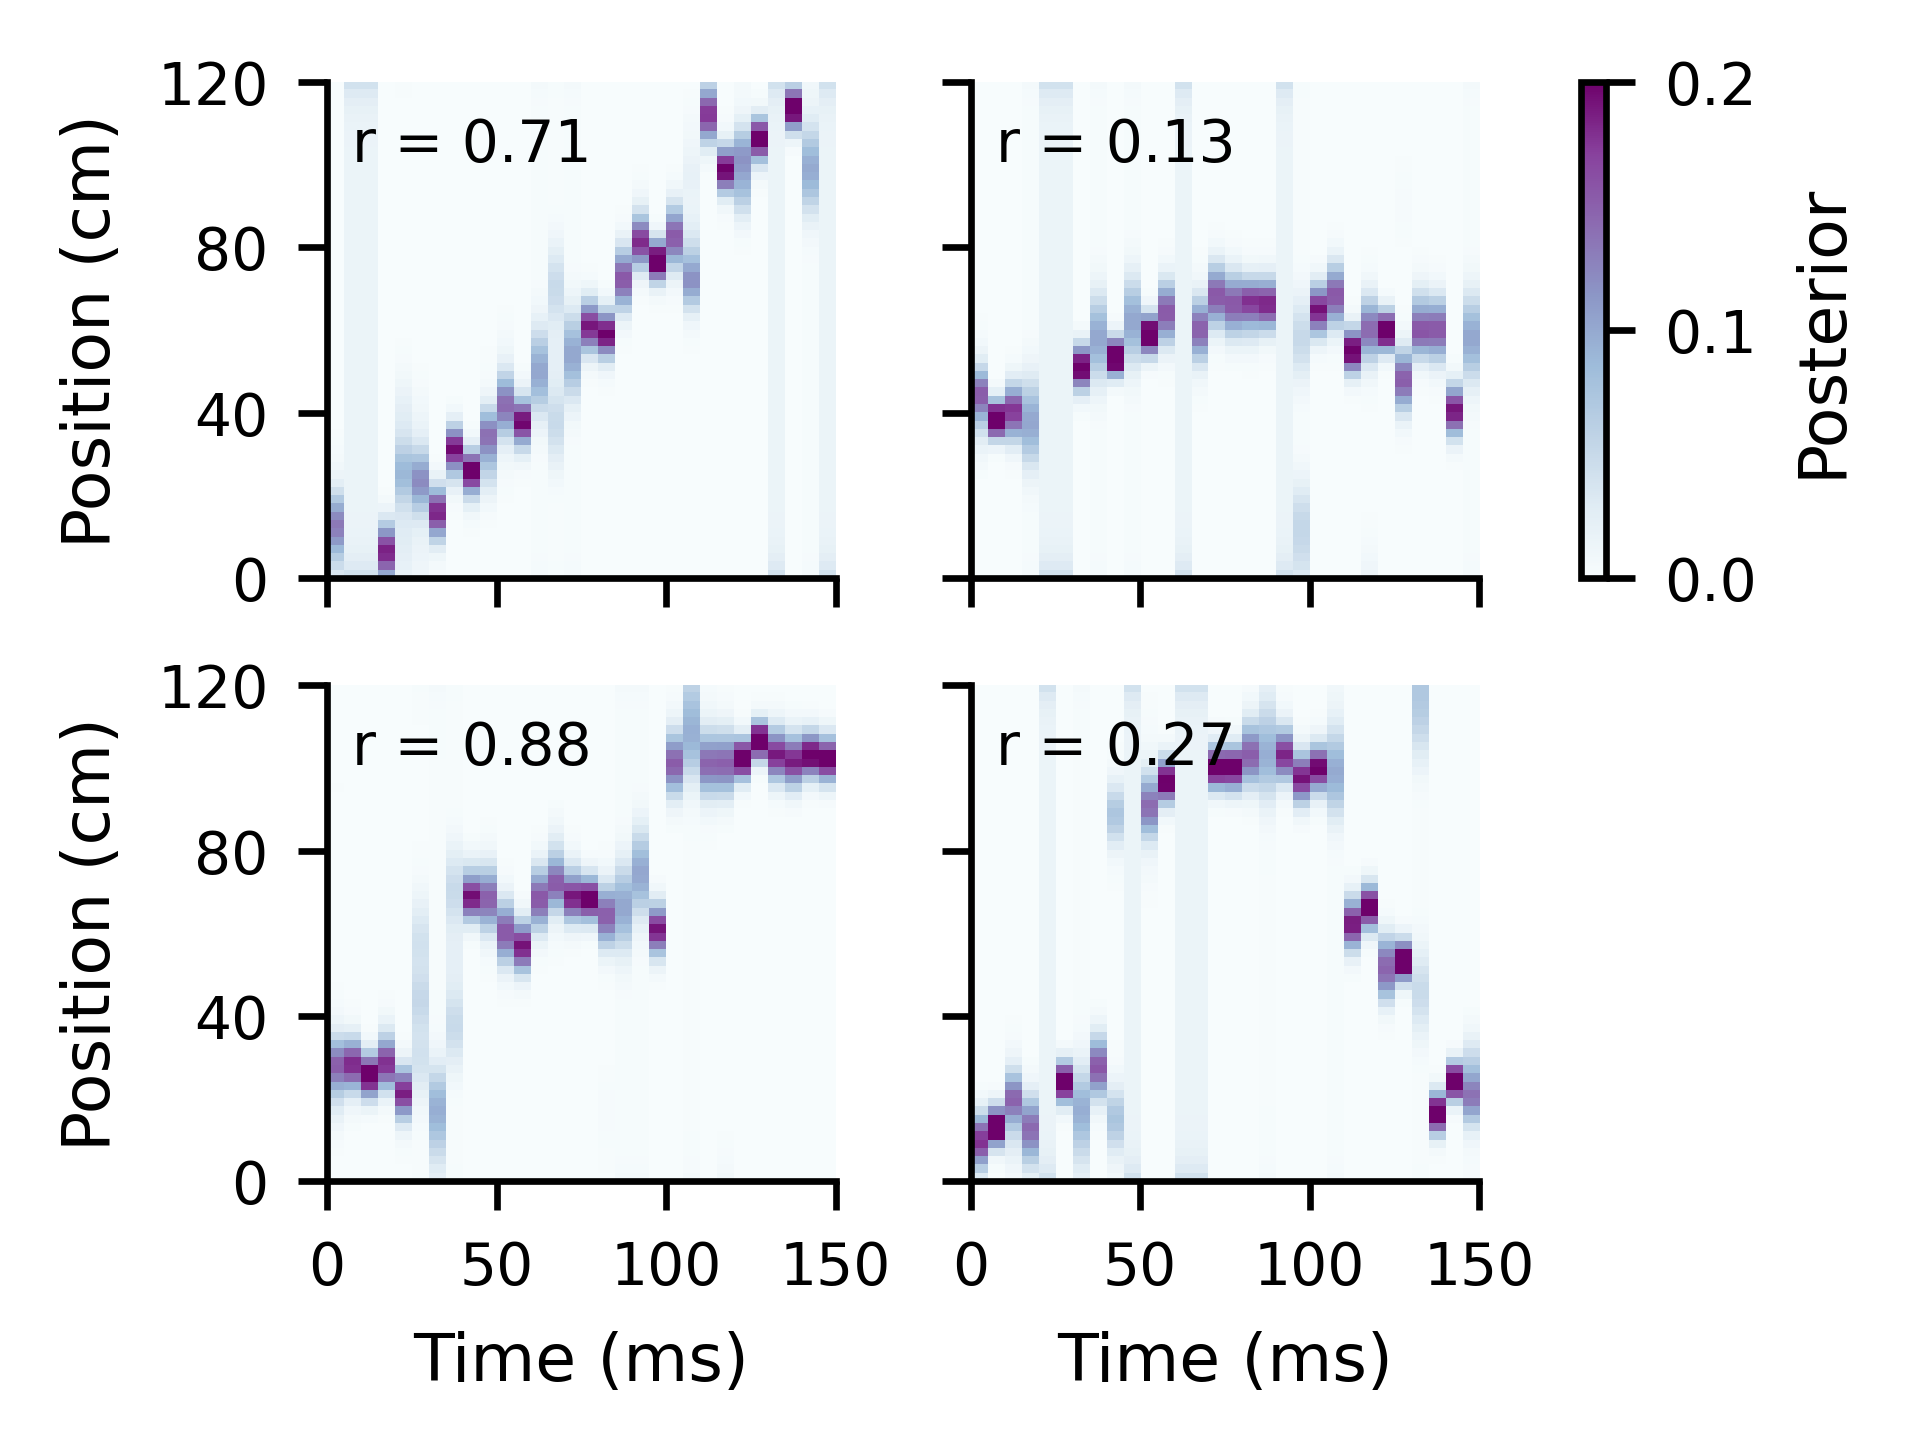

In [5]:
# The four decoded posteriors together on one color scale: linear and three jumps on
# top, the smooth reversal and the TCM-SR jumpy reversal below.
GRID = [("linear", "Linear"), ("reversal", "Reversal"), ("jumps", "Jumps"),
        ("tcmsr", "TCM-SR rollout")]

fig, axes = plt.subplots(2, 2, figsize=(4.0/1.3, 3.0/1.3), dpi=600, sharex=True, sharey=True,
                         layout="constrained")
for ax, (name, title) in zip(axes.ravel(), GRID):
    post, wc = PANELS[name]
    im = draw_posterior(ax, post, seq_duration, wc)
    # ax.set_title(title, fontsize=LABEL_FS)
for ax in axes[-1]:
    ax.set_xlabel("Time (ms)", fontsize=LABEL_FS)
for ax in axes[:, 0]:
    ax.set_ylabel("Position (cm)", fontsize=LABEL_FS)
add_posterior_colorbar(fig, im, axes[0])

# plt.savefig("fig1_posterior_grid.pdf", bbox_inches="tight")
plt.show()

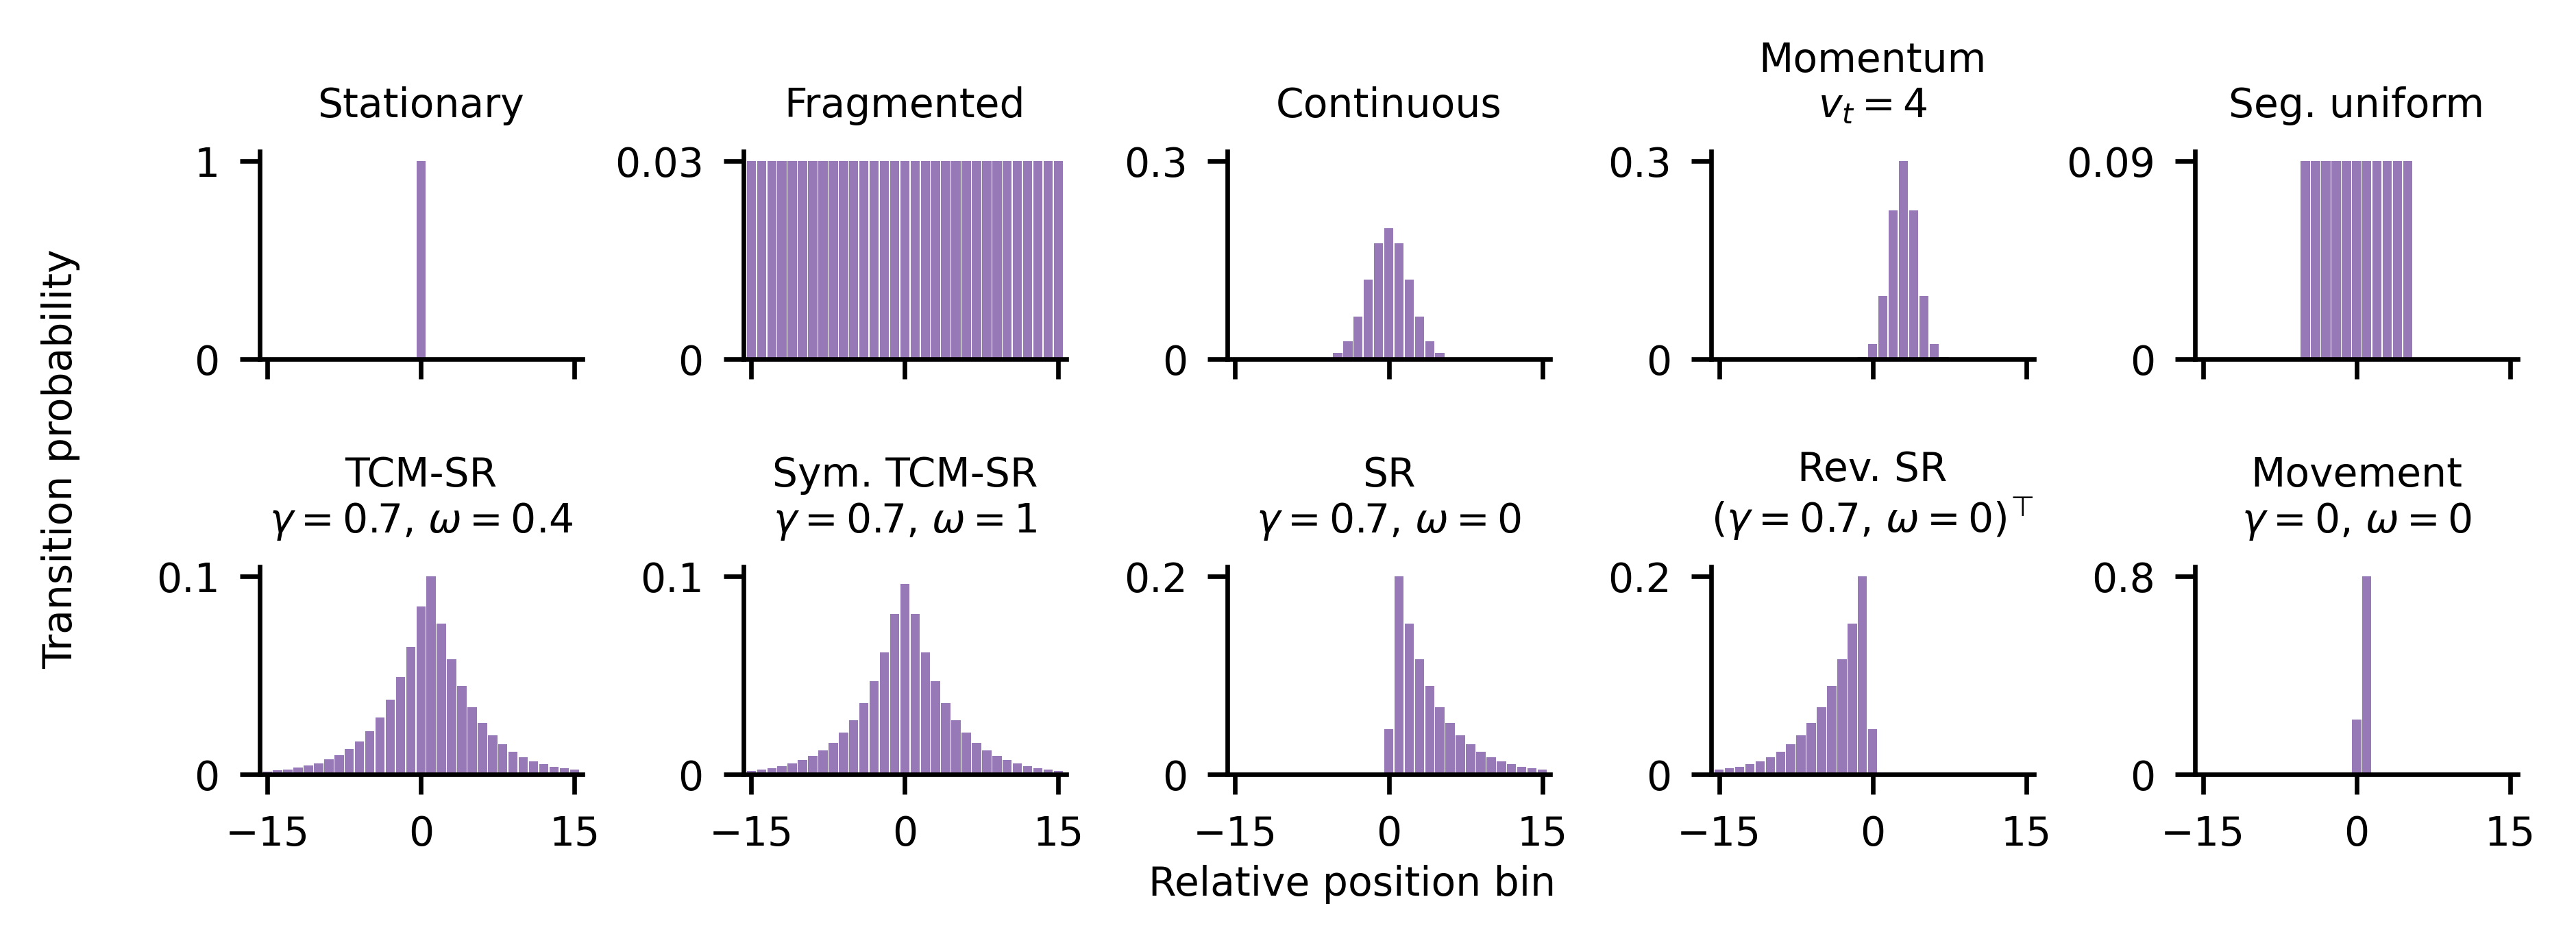

In [6]:
# All ten kernels as PMFs, two rows: the behavior-based SR family on top, the heuristic
# kernels below. Continuous sits between its two relatives (Seg. uniform, its sigma -> inf
# limit; Momentum, which reduces to it at a = 0) so the nesting can be annotated.
from replay_hmm.plots.labels import kernel_label

# The SR family as one construction, (gamma, omega, transposed) per kernel:
#   A = (1 - omega) M + omega M.T @ M,   M = (I - gamma T)^{-1} T
# omega = 0 is the SR and omega = 1 the symmetric TCM-SR; gamma = 0 collapses M to T
# (Movement); transposing T gives the reverse SR. Titles are printed from this table, so
# they cannot disagree with the panels.
gamma = 0.7
SR_FAMILY = {
    "sticky_TCMSR":       (gamma, 0.4, False),
    "sticky_TCMSR_sym":   (gamma, 1.0, False),
    "sticky_SR_rev":      (gamma, 0.0, True),
    "sticky_SR":          (gamma, 0.0, False),
    "movement_empirical": (0.0, 0.0, False),
}

def sr_family_kernel(gamma, omega, transposed):
    # sr_family_kernels takes alpha = 1 - omega; transposing T on the ring is the same as
    # swapping the forward and backward step probabilities.
    p_back, p_fwd = (0.9, 0.0) if transposed else (0.0, 0.9)
    return sr_family_kernels(positions, gamma=gamma, alpha=1 - omega,
                             p_back=p_back, p_fwd=p_fwd)[2]

def sr_family_title(name):
    gamma, omega, transposed = SR_FAMILY[name]
    if transposed:   # the same kernel, transposed
        return rf"{kernel_label(name)}" "\n" rf"$(\gamma={gamma:g}$, $\omega={omega:g})^{{\!\top}}$"
    return rf"{kernel_label(name)}" "\n" rf"$\gamma={gamma:g}$, $\omega={omega:g}$"

# Momentum is second order, so its panel is drawn at one fixed incoming velocity, printed
# in its title.
MOMENTUM = dict(a=0.75, jump_sd=2.0, v_t=4)

def momentum_kernel(pos, a, jump_sd, v_t):
    """Second-order kernel s_{t+1} ~ N(s_t + a v_t, q), q = jump_sd^2 (1 - a^2).

    v_t = s_t - s_{t-1} is the incoming velocity; drawn at s_t = 0, so the last step moved
    +v_t bins. jump_sd matches Continuous's sigma, so the two share a jump marginal.
    """
    mean = a * v_t
    sd = jump_sd * np.sqrt(1 - a ** 2)
    k = np.exp(-0.5 * ((pos - mean) / sd) ** 2)
    return k / k.sum()

def segment_uniform_kernel(pos, seg=(-5, 5)):
    """Uniform within the current segment, zero outside: Continuous's sigma -> inf limit."""
    k = ((pos >= seg[0]) & (pos <= seg[1])).astype(float)
    return k / k.sum()

kernels10 = {name: sr_family_kernel(*params) for name, params in SR_FAMILY.items()}
kernels10.update({
    "stationary":         kernels["Stationary"],
    "fragmented":         kernels["Fragmented"],
    "segment_uniform":    segment_uniform_kernel(positions),
    "continuous_EM":      kernels["Continuous"],
    "momentum":           momentum_kernel(positions, **MOMENTUM),
})
layout = [
    ["stationary", "fragmented", "continuous_EM", "momentum", "segment_uniform"],
    ["sticky_TCMSR", "sticky_TCMSR_sym", "sticky_SR", "sticky_SR_rev", "movement_empirical"],
]
row_titles = [] # ["Behavior-based", "Heuristic"]
# Siblings share a y-axis so their mass is directly comparable; everything else gets its
# own scale (one shared row axis would flatten SR/TCM-SR under Movement's 0.78 peak).
sharey_groups = [
    ("sticky_TCMSR", "sticky_TCMSR_sym"),
    ("sticky_SR", "sticky_SR_rev"),
    ("continuous_EM", "momentum"),
]
ymax = {name: k.max() for name, k in kernels10.items()}
for group in sharey_groups:
    for name in group:
        ymax[name] = max(kernels10[g].max() for g in group)

fig, axes = plt.subplots(
    2, 5, figsize=(18/2.54, 5/2.54), sharex=True,
    gridspec_kw={"hspace": 1.0, "wspace": 0.5},
    dpi=600
)

for ax, name in zip(axes.ravel(), sum(layout, [])):
    ax.bar(positions, kernels10[name], width=0.9, alpha=0.9, color="#8c6bb1")
    if name in SR_FAMILY:
        title = sr_family_title(name)
    elif name == "momentum":
        title = f"{kernel_label(name)}\n$v_t={MOMENTUM['v_t']:g}$"
    else:
        title = kernel_label(name)
    ax.set_title(title, loc="center", fontsize=7)
    ax.set_ylim(0, 1.05 * ymax[name])
    ax.set_yticks([0, ymax[name]], ["0", f"{ymax[name]:.1g}"])   # 0 and the peak
    ax.tick_params(labelsize=7)
    ax.margins(x=0.01)

for ax in axes[-1]:
    ax.set_xticks([-HALF_WIDTH, 0, HALF_WIDTH])
fig.supxlabel("Relative position bin", fontsize=7, y=-0.05)
fig.supylabel("Transition probability", x=0.05, fontsize=7)

# Row titles centered over each row, just above its tallest panel title (titles with a
# parameter line run to two lines, so a fixed offset from the axes would collide with them).
fig.canvas.draw()   # finalize axes and title positions before reading them
to_fig = fig.transFigure.inverted()
for i, rt in enumerate(row_titles):
    left, right = axes[i, 0].get_position(), axes[i, -1].get_position()
    top = max(to_fig.transform(ax.title.get_window_extent().get_points())[1, 1]
              for ax in axes[i])
    fig.text((left.x0 + right.x1) / 2, top + 0.02, rt,
             ha="center", va="bottom", fontsize=10)

# plt.savefig("fig1_kernels_pmf_all10.pdf", bbox_inches="tight")
plt.show()

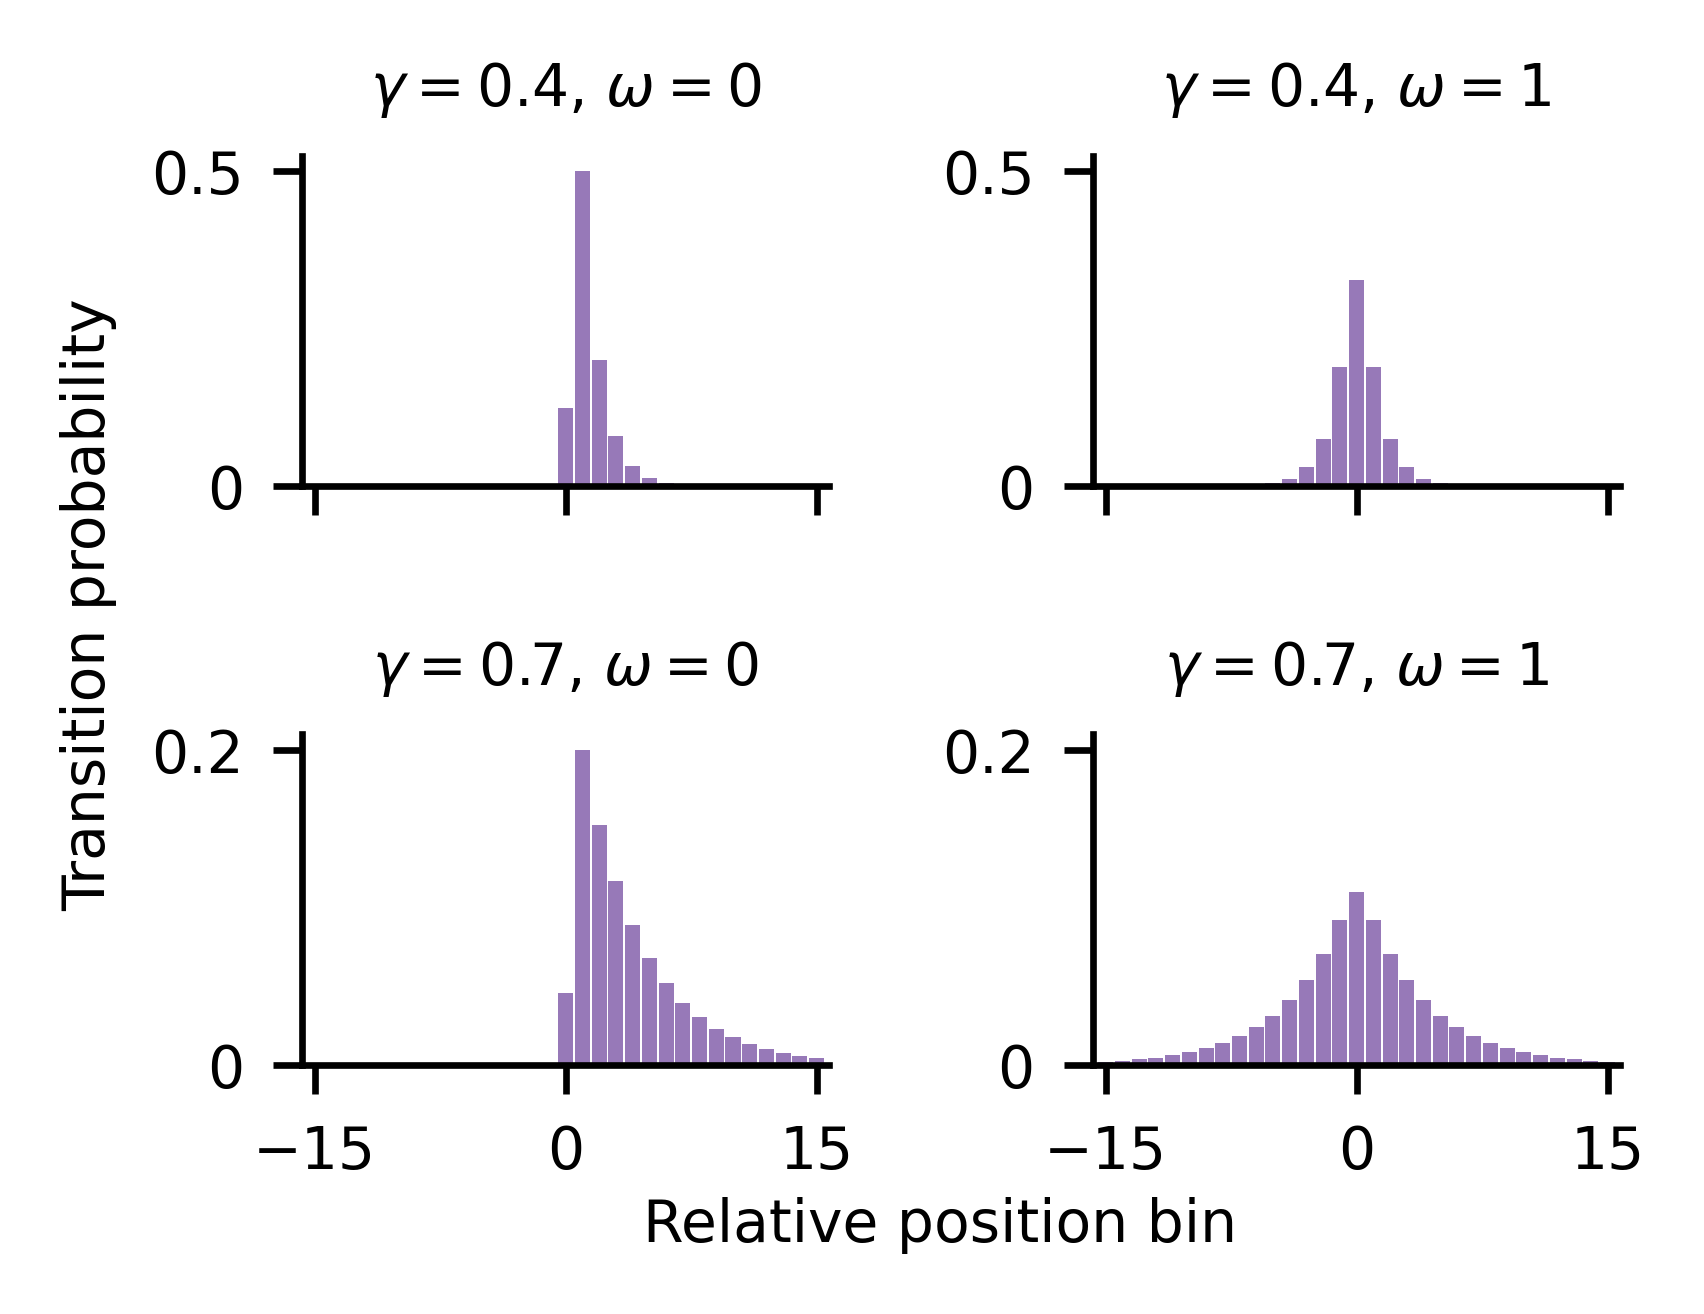

In [7]:
# The SR -> M^T M continuum: the SR (omega = 0) on the left, the pure M^T M term
# (omega = 1) on the right, and two intermediate mixtures between them; one row per gamma
# (top row is the ten-kernel figure's gamma). Each panel is the same sr_family_kernel
# construction as the ten-kernel figure above. The mixture is row-normalized after mixing,
# and M^T M's rows sum to 1/(1-gamma) times M's, so at large gamma intermediate omegas
# already lean toward the M^T M end.
OMEGAS = [0.0, 1.0]

GAMMAS = [gamma, 0.4][::-1]
omega_kernels = {(g, omega): sr_family_kernel(g, omega, False)
                 for g in GAMMAS for omega in OMEGAS}
end_labels = {0.0: r"SR ($M$)", 1.0: r"$M^{\top}M$"}

fig, axes = plt.subplots(
    len(GAMMAS), len(OMEGAS), figsize=(18/2.54 * len(OMEGAS) / 5, 5/2.54), sharex=True,
    gridspec_kw={"hspace": 0.75, "wspace": 0.5},
    dpi=600
)

for row, g in zip(axes, GAMMAS):
    # One y-axis per row: mass moving along the omega sweep is directly comparable.
    ymax_row = max(omega_kernels[g, omega].max() for omega in OMEGAS)
    for ax, omega in zip(row, OMEGAS):
        ax.bar(positions, omega_kernels[g, omega], width=0.9, alpha=0.9, color="#8c6bb1")
        title = rf"$\gamma={g:g}$, $\omega={omega:g}$"
        # if omega in end_labels:
        #     title = end_labels[omega] + "\n" + title
        ax.set_title(title, loc="center", fontsize=7)
        ax.set_ylim(0, 1.05 * ymax_row)
        ax.set_yticks([0, ymax_row], ["0", f"{ymax_row:.1g}"])
        ax.tick_params(labelsize=7)
        ax.margins(x=0.01)

for ax in axes[-1]:
    ax.set_xticks([-HALF_WIDTH, 0, HALF_WIDTH])
fig.supxlabel("Relative position bin", fontsize=7, y=-0.05)
# Right-align the shared y label just left of the first column's tick labels, wherever
# the figure size and panel count put them.
fig.canvas.draw()   # tick-label extents are only known after a draw
to_fig = fig.transFigure.inverted()
left = min(to_fig.transform(ax.get_tightbbox().get_points())[0, 0] for ax in axes[:, 0])
fig.supylabel("Transition probability", x=left - 0.02, ha="right", fontsize=7)

# plt.savefig("fig1_kernels_omega_gamma_sweep.pdf", bbox_inches="tight")
plt.show()

# The gamma = 0.7 ends are the SR and symmetric TCM-SR panels of the ten-kernel figure.
assert np.allclose(omega_kernels[gamma, 0.0], kernels10["sticky_SR"])
assert np.allclose(omega_kernels[gamma, 1.0], kernels10["sticky_TCMSR_sym"])